In [119]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [120]:
from pygraphon.graphons.StepGraphon import StepGraphon
import numpy as np
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt
from pygraphon.utils.utils_graph import edge_density
from tqdm import tqdm

In [121]:
#Set the matrix of theta
graphon_matrix = np.array([[0.8,0.1,0.1],[0.1,0.8,0.1],[0.1,0.1,0.8]])
#set up normalised graphon with graphon
graphon = StepGraphon(graphon_matrix,1/3)

In [122]:
#original integral and normalised one
print(graphon.integral(graphon_matrix), graphon.integral())

0.33333333333333337 1.0


In [123]:
#new graphon after normalisation
graphon.graphon

array([[2.4, 0.3, 0.3],
       [0.3, 2.4, 0.3],
       [0.3, 0.3, 2.4]])

In [124]:
from pygraphon.plots.plot_matrices import spy
import matplotlib.pyplot as plt

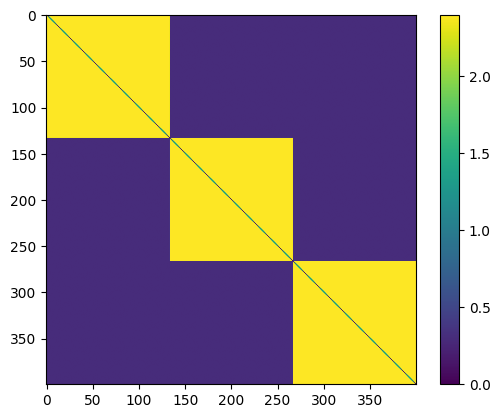

In [125]:
plt.imshow(graphon._get_edge_probabilities(400,False,True))
plt.colorbar()
plt.show()

In [126]:
#Draw a graph from the graphon with a given density and number of vertices, see GraphonAbstract.py
n=300
rho_n=0.3
A = graphon.draw(rho = rho_n,n = n, exchangeable=False)

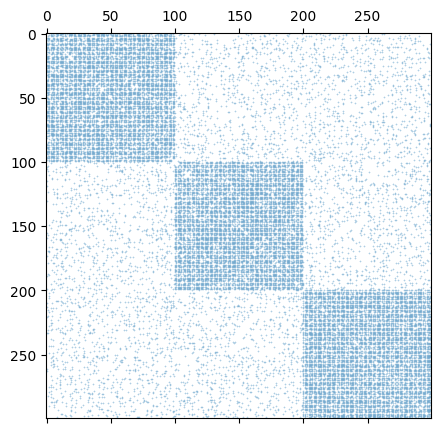

In [127]:
fig, ax = spy(A)#from pygraphon.plots.plot_matrices
plt.show()

In [149]:
edge_density(A)

In [129]:
from pygraphon.estimators.HistogramEstimator import HistogramEstimator
from pygraphon.estimators.MomentEstimator import MomentEstimator, SimpleMomentEstimator

In [130]:
hist = HistogramEstimator()
hist_epprox = hist.estimate(adjacency_matrix= A, bandwidthHist= None)

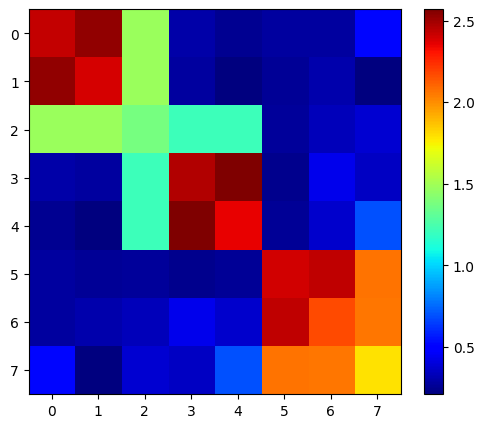

In [131]:
from pygraphon.plots.plots_graphon import plot
plot(hist_epprox)
plt.show()

In [132]:
from pygraphon.subgraph_isomorphism.CycleCount import CycleCount
counter = CycleCount(L = 9)

In [133]:
momentestimator = SimpleMomentEstimator(3)
mome_simple_approx = momentestimator.estimate(adjacency_matrix= A)

c:\Users\verdeyme\Desktop\Code\pygraphon\env\lib\site-packages\scipy\optimize\_minpack_py.py:175: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last five Jacobian evaluations.
  warnings.warn(msg, RuntimeWarning)


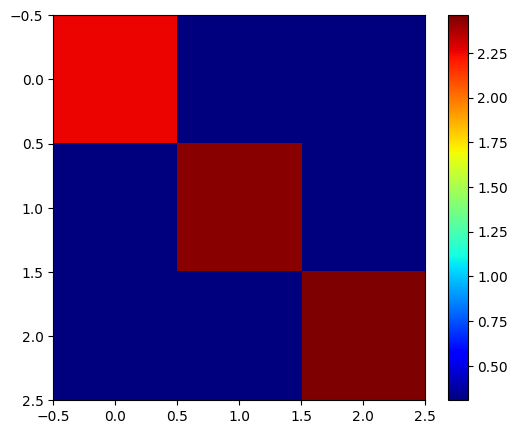

In [134]:
plot(mome_simple_approx)
plt.show()

In [135]:
mome_simple_approx.graphon

array([[2.25470685, 0.30805788, 0.30805788],
       [0.30805788, 2.4373731 , 0.30805788],
       [0.30805788, 0.30805788, 2.45957276]])

In [136]:
mome_simple_approx.integral()

1.0000000000000002

Clustering the tiles independently (i.e. without structure)

In [137]:
from sklearn.cluster import KMeans
#Extract tiles and reshape
nrow_tile = hist_epprox.graphon.shape[0]
flat_graphon = hist_epprox.graphon[np.triu_indices(nrow_tile)]
#Clustering according to kmeans
max_k = int(nrow_tile*(nrow_tile+1)/2)#number of individual tile
avr_graphon = np.asarray([flat_graphon.copy() for k in range(max_k)])#copies for different number of clusters
for i in range(max_k-1):
    if i==0:
        avr_graphon[i]=edge_density(A)*np.ones_like(flat_graphon)
    else:
        kmeans = KMeans(n_clusters=i+1, random_state=0).fit(flat_graphon.reshape(-1,1))
        #Smooth using mean by memberhsip
        for j in range(i+1):#average tiles of same community
            avr_graphon[i][kmeans.labels_==j] = flat_graphon[kmeans.labels_==j].mean()

In [138]:
#Reverse flattening back to 2d
KM_smooth_graphon = np.zeros((max_k,nrow_tile, nrow_tile))#initiate matrix containing smooth graphon
i,j = np.triu_indices(nrow_tile)
KM_smooth_graphon[:,i,j]=avr_graphon

In [139]:
#Make it symmetric
#Extract diagonal
i,j=np.diag_indices(nrow_tile)
diag_KM_vec=np.diagonal(KM_smooth_graphon, axis1=1,axis2=2)
#make 3d array with diagonal in axis 1&2
diag_km=np.zeros((max_k, nrow_tile,nrow_tile))
diag_km[:,i,j]=diag_KM_vec

sym_KM_smooth_graphon= KM_smooth_graphon+np.transpose(KM_smooth_graphon, (0,2,1))-diag_km

In [ ]:
import matplotlib.pyplot as plt

which_k = 2
H = sym_KM_smooth_graphon[which_k-1]

fig = plt.figure(figsize=(6, 3.2))

ax = fig.add_subplot(111)
ax.set_title("Smoothed hist for k=%.i" % which_k)
plt.imshow(H)
ax.set_aspect('equal')

cax = fig.add_axes([0.12, 0.1, 0.78, 0.8])
cax.get_xaxis().set_visible(False)
cax.get_yaxis().set_visible(False)
cax.patch.set_alpha(0)
cax.set_frame_on(False)
plt.colorbar(orientation='vertical')
plt.show()

In [183]:
#Comparing p_ij's
block_size = (300/(nrow_tile*np.ones(nrow_tile))).astype(int)
block_size[-1] = n- np.sum(block_size[0:-1])
#only for one block so far, thus the [2,i,j]
block_list = np.array([[sym_KM_smooth_graphon[2,i,j]*np.ones((block_size[i], block_size[j])) 
for j in range(len(block_size))]for i in range(len(block_size))], dtype=object)
print()